# MATPLOTLIB MASTERY — NOTEBOOK 7
## Chapters 56–65: Threshold Visualization → Regression Visualization → Residual Analysis → Feature Importance → Model Comparison → Hyperparameter Visualization → Learning Curves → Validation Curves → Experiment Visualization → Error Analysis

Continuing directly from Notebook 6, reusing its trained `log_reg` / `rf_clf` classifiers where relevant, and introducing a real regression model for Chapters 57–58.

### Progress Tracker (this notebook)
- [x] Chapter 56 — Threshold Visualization
- [x] Chapter 57 — Regression Model Visualization
- [x] Chapter 58 — Residual Analysis
- [x] Chapter 59 — Feature Importance Visualization
- [x] Chapter 60 — Model Comparison Visualization
- [x] Chapter 61 — Hyperparameter Visualization
- [x] Chapter 62 — Learning Curves
- [x] Chapter 63 — Validation Curves
- [x] Chapter 64 — Experiment Visualization
- [x] Chapter 65 — Error Analysis


In [15]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)

# Rebuild Notebook 6's classification setup so this notebook runs standalone
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import precision_recall_curve

X_clf, y_clf = make_classification(
    n_samples=1000, n_features=10, n_informative=6, n_redundant=2,
    weights=[0.75, 0.25], random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(X_clf, y_clf, test_size=0.3, random_state=42, stratify=y_clf)

log_reg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)

y_proba_lr = log_reg.predict_proba(X_test)[:, 1]
y_proba_rf = rf_clf.predict_proba(X_test)[:, 1]

print("Setup complete —", X_test.shape[0], "test samples,", y_test.mean().round(3), "positive rate.")


Setup complete — 300 test samples, 0.253 positive rate.


---
# CHAPTER 56 — THRESHOLD VISUALIZATION

## 1. Concept
Precision, Recall, and F1 all change as the classification threshold moves — plotting all three **against the threshold itself** (rather than against each other, as ROC/PR do) directly supports choosing a specific, business-appropriate operating point.

## 2. Why It Matters
Neither the ROC nor PR curve (Chapters 54–55) directly tells you *which threshold* to actually deploy — they show the tradeoff curve, but the threshold values themselves are hidden in an auxiliary array. This chapter makes the threshold the explicit x-axis, turning the abstract tradeoff into an actionable business decision tool.


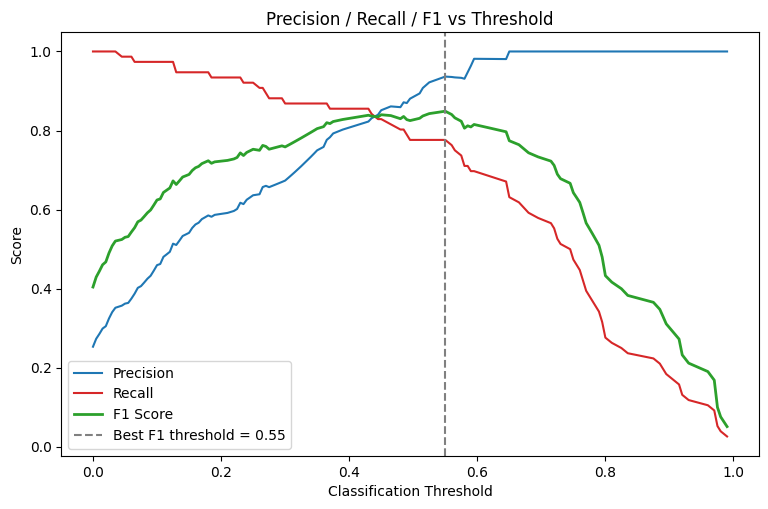

In [16]:
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_proba_rf)

# precision_recall_curve returns one MORE precision/recall point than thresholds
# (it appends a final (precision=1, recall=0) point with no corresponding threshold) — trim to align them
precision_vals = precision_vals[:-1]
recall_vals = recall_vals[:-1]

f1_vals = 2 * (precision_vals * recall_vals) / (precision_vals + recall_vals + 1e-9)   # avoid div-by-zero

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(pr_thresholds, precision_vals, label="Precision", color="tab:blue")
ax.plot(pr_thresholds, recall_vals, label="Recall", color="tab:red")
ax.plot(pr_thresholds, f1_vals, label="F1 Score", color="tab:green", linewidth=2)

best_f1_idx = np.argmax(f1_vals)
ax.axvline(pr_thresholds[best_f1_idx], color="gray", linestyle="--",
           label=f"Best F1 threshold = {pr_thresholds[best_f1_idx]:.2f}")

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 vs Threshold")
ax.legend()
plt.show()


### Line-by-Line Explanation
- `precision_recall_curve()` returns arrays that are **one element longer** for precision/recall than for thresholds (it appends a final, threshold-less `(precision=1.0, recall=0.0)` boundary point) — trimming with `[:-1]` is a necessary, easy-to-miss alignment step before plotting all three series against the same threshold x-axis.
- `f1_vals = 2 * (P * R) / (P + R + 1e-9)` — the harmonic mean of precision and recall, vectorized across every threshold in one NumPy expression; the tiny `+1e-9` avoids a division-by-zero warning at thresholds where both precision and recall happen to be exactly zero.
- `np.argmax(f1_vals)` — finds the single threshold that maximizes F1, a common (though not universally "correct" — see below) default choice for picking an operating threshold when no specific business cost asymmetry is known.

### Interpretation
As threshold increases (the model becomes "pickier" about calling something positive), precision typically rises (fewer, more confident positive predictions) while recall falls (more true positives get missed) — the classic tradeoff. The vertical line marks where F1 (a balanced compromise) peaks, but this is only the *default* answer, not necessarily the *right* one for every business context.

### Common Mistakes
- Forgetting the array-length mismatch between `precision_recall_curve()`'s outputs and silently misaligning precision/recall against the wrong threshold values.
- Always defaulting to the "best F1" threshold without considering the actual business cost asymmetry between false positives and false negatives — F1 weights precision and recall *equally*, which is rarely the true business cost structure (e.g., in fraud detection, missing fraud (FN) is often far costlier than a false alarm (FP), meaning a threshold favoring higher recall over F1-optimal balance might be the actually correct choice).

### Best Practices
- Use this chart as a starting point for a **business conversation** about acceptable precision/recall tradeoffs, not as a fully automated threshold-selection tool.
- When a specific cost ratio between FP and FN is known (e.g., "a missed fraud case costs 10x a false alarm"), compute and optimize a cost-weighted metric instead of plain F1, and mark *that* optimal threshold instead.

### Interview Insight
**Q: Why shouldn't you always deploy a classifier at its "best F1" threshold?**
A: F1 assumes precision and recall are equally important, which is rarely true in practice — different business contexts weight false positives and false negatives very differently (e.g., missing a fraud case vs. a false fraud alert have very different costs). The threshold-vs-metric chart should inform a deliberate choice based on the actual cost asymmetry of the specific problem, not be treated as producing one universally "optimal" answer via F1 alone.

### Mini Exercise
Compute a cost-weighted score `score = 2*recall_vals + precision_vals` (weighting recall twice as important as precision — a plausible choice if false negatives are twice as costly as false positives) and find/mark the threshold that maximizes it instead of plain F1.

### Quiz (Chapter 56)
1. Why must you trim `precision_vals`/`recall_vals` before plotting them against `pr_thresholds`?
2. What does a rising threshold typically do to precision and recall respectively, and why?
3. Why is "best F1 threshold" not automatically the correct business choice?


---
# CHAPTER 57 — REGRESSION MODEL VISUALIZATION

## 1. Concept
For a continuous target, the three foundational diagnostic charts are: **Actual vs Predicted** (scatter, with a perfect-prediction reference line), the **residual plot** (errors vs. predicted value), and the **error distribution** (histogram of residuals).

## 2. Why It Matters
RMSE/MAE alone tell you *how much* error exists on average, but not *where* or *in what pattern* — these three charts are how you diagnose *why* a regression model is wrong, not just confirm that it is.


In [17]:
X_reg, y_reg = make_regression(n_samples=400, n_features=8, n_informative=5, noise=15, random_state=7)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.3, random_state=7)

lin_reg = LinearRegression().fit(Xr_train, yr_train)
rf_reg = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=7).fit(Xr_train, yr_train)

yr_pred_lin = lin_reg.predict(Xr_test)
yr_pred_rf = rf_reg.predict(Xr_test)

print("Linear Regression RMSE:", np.sqrt(np.mean((yr_test - yr_pred_lin) ** 2)).round(2))
print("Random Forest RMSE:", np.sqrt(np.mean((yr_test - yr_pred_rf) ** 2)).round(2))


Linear Regression RMSE: 15.8
Random Forest RMSE: 45.65


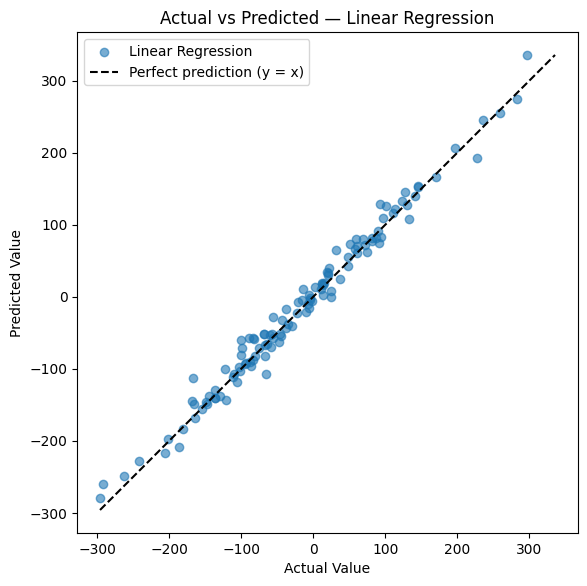

In [18]:
fig, ax = plt.subplots(figsize=(7, 6.5))

ax.scatter(yr_test, yr_pred_lin, alpha=0.6, color="tab:blue", label="Linear Regression")

lims = [min(yr_test.min(), yr_pred_lin.min()), max(yr_test.max(), yr_pred_lin.max())]
ax.plot(lims, lims, color="black", linestyle="--", linewidth=1.5, label="Perfect prediction (y = x)")

ax.set_xlabel("Actual Value")
ax.set_ylabel("Predicted Value")
ax.set_title("Actual vs Predicted — Linear Regression")
ax.legend()
ax.set_aspect("equal", adjustable="box")   # critical: keeps the reference line at a true 45 degrees
plt.show()


### Line-by-Line / Parameter Explanation
- `lims = [min(...), max(...)]` — computed dynamically from both actual **and** predicted values, not just one or the other, so the perfect-prediction reference line always spans the full visible range of the data regardless of whether the model over- or under-predicts at the extremes.
- `ax.set_aspect("equal", adjustable="box")` — **essential**, and frequently skipped: without it, Matplotlib's default auto-scaling can stretch the x and y axes independently, visually distorting the "45-degree line" into an angle that no longer looks like perfect prediction, misleading the eye about how good the fit actually is.

### Interpretation
Points clustering tightly around the diagonal line indicate accurate predictions; systematic deviation — e.g., points consistently *above* the line at high actual values — indicates the model **under-predicts** large values (a common pattern for models under-fitting the tails of a distribution), directly actionable information that RMSE alone cannot convey.

### Common Mistakes
- Omitting `ax.set_aspect("equal")` — the single most common technical mistake in actual-vs-predicted plots, since it silently distorts the visual reference for "perfect prediction."
- Computing the reference line's range from only `yr_test` (actual values) and not also `yr_pred` — if predictions extend beyond the actual range, part of the plot ends up with no reference line, making some points impossible to judge against a "perfect" baseline.
- Showing an actual-vs-predicted plot without RMSE/MAE stated alongside it — the visual and the numeric summary should always be presented together, each catching what the other misses.

### Best Practices
- Always include the diagonal reference line, and always fix the aspect ratio.
- Present alongside a residual plot (next chapter) for the complete diagnostic picture.

### Interview Insight
**Q: Why is `ax.set_aspect('equal')` important on an actual-vs-predicted scatter plot specifically?**
A: The plot's core interpretive device is the 45° diagonal reference line representing "perfect prediction" — if the x and y axes are allowed to auto-scale independently (the Matplotlib default), that line can visually render at some other angle even though the data itself is unchanged, misleading a viewer about how tightly points actually cluster around true perfect prediction. Fixing the aspect ratio to `'equal'` guarantees the diagonal always visually represents a true 1:1 relationship.

### Mini Exercise
Recreate this plot for `yr_pred_rf` (the Random Forest regressor) instead, and compare — does it cluster more tightly around the diagonal than the Linear Regression model, consistent with its lower RMSE computed above?

### Quiz (Chapter 57)
1. What does `ax.set_aspect('equal')` prevent, and why does it matter specifically for this chart?
2. Why must the reference line's range be computed from both actual and predicted values?
3. What kind of systematic pattern (not just scatter) would indicate the model under-predicts large values?


---
# CHAPTER 58 — RESIDUAL ANALYSIS

## 1. Concept
**Residual = Actual − Predicted.** A residual plot (predicted value on x, residual on y) reveals patterns an actual-vs-predicted plot can hide — specifically whether errors are randomly scattered (good) or systematically structured (a sign the model is missing something).

## 2. Why It Matters
A "good" regression model's residuals should look like **structureless random noise**, centered at zero, with roughly constant spread — any visible pattern (a curve, a funnel shape, a trend) is direct evidence the model is misspecified in some diagnosable way.


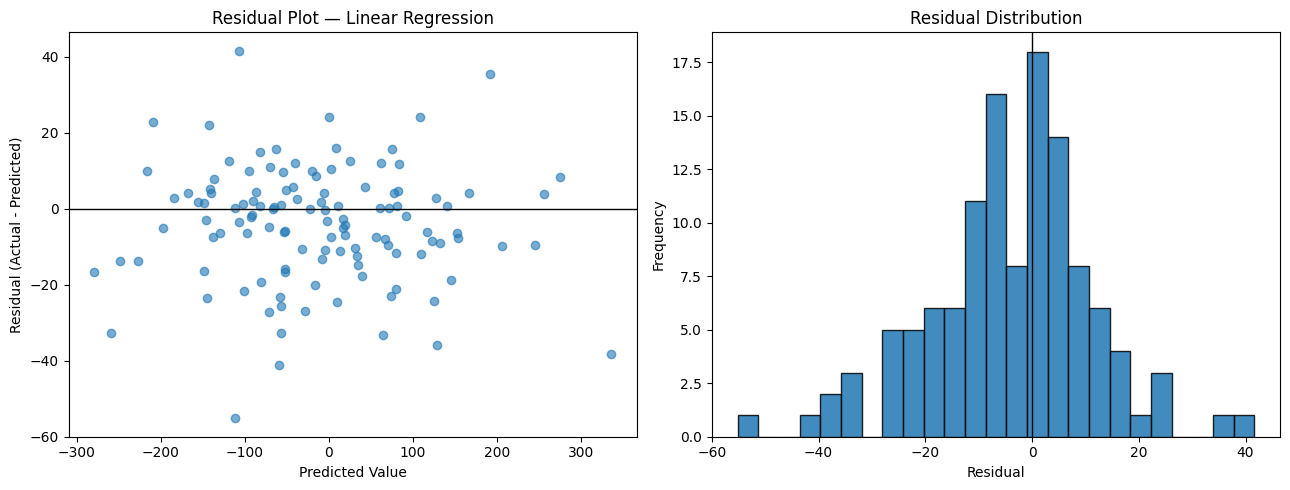

In [19]:
residuals_lin = yr_test - yr_pred_lin

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(yr_pred_lin, residuals_lin, alpha=0.6, color="tab:blue")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Predicted Value")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residual Plot — Linear Regression")

axes[1].hist(residuals_lin, bins=25, color="tab:blue", edgecolor="black", alpha=0.85)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `residuals_lin = yr_test - yr_pred_lin` — the sign convention matters and should be stated explicitly in any report: a **positive** residual here means the model **under-predicted** (actual was higher than predicted); some codebases use the opposite convention (`predicted - actual`), so always label clearly.
- Left panel — residuals plotted against **predicted** value (not actual value) is the conventional choice, because it directly shows whether error magnitude/direction depends on the model's own output range, which is the actionable diagnostic question ("is my model systematically worse for certain predicted ranges?").
- Right panel — the residual histogram should be roughly symmetric and centered at zero for a well-specified model; a skewed residual distribution suggests the model's errors aren't just noise but have a systematic directional bias in some regime.

### Diagnosing Specific Patterns — a Visual Reference
| Residual plot pattern | Diagnosis |
|---|---|
| Random scatter around 0, constant spread | Good — no obvious remaining structure |
| Funnel shape (spread increases with predicted value) | **Heteroscedasticity** — error variance isn't constant; consider a transform (e.g., log target) or a different model |
| Curved/U-shaped pattern | Model is missing a non-linear relationship the features actually have with the target |
| Residuals trend up or down with predicted value | Systematic bias — the model consistently over/under-predicts in some range |

### Interpretation
Check the left panel specifically for a "funnel" widening toward higher predicted values (heteroscedasticity) or any visible curve (missing non-linearity) — either pattern would tell you precisely what to fix next (a transform, additional features, or a fundamentally different model class), which a single RMSE number could never suggest on its own.

### Common Mistakes
- Only checking RMSE/MAE and never actually looking at the residual plot — misses systematic, fixable model misspecification entirely.
- Plotting residuals against the **actual** value instead of the **predicted** value — a subtle but real difference; predicted-value residual plots are the standard convention because they reflect what the model itself is doing, not what the (unknown, at deployment time) ground truth happens to be.
- Not checking residuals against individual **features** as well (not shown above, but a natural extension) — sometimes a pattern only appears against one specific input feature, not against the predicted value overall.

### Best Practices
- Always generate both the scatter (predicted vs residual) and the histogram (residual distribution) as a matched pair — same "two complementary views" principle from Chapter 42's univariate analysis, now applied to model errors specifically.
- Explicitly state the residual sign convention used (`actual - predicted` vs the reverse) in any shared analysis, since it flips the interpretation of "positive" and "negative" residuals.

### Interview Insight
**Q: Your regression model's residual plot shows a clear funnel shape — the spread of residuals grows as predicted values increase. What does this tell you, and what might you do about it?**
A: This is heteroscedasticity — the model's error variance is not constant across the range of predictions, which violates a standard regression assumption and means prediction intervals/confidence should not be treated as uniform across the output range. Common responses include applying a variance-stabilizing transform to the target (e.g., `log(y)`), using a model that can natively handle heteroscedastic noise, or explicitly modeling the variance itself (e.g., quantile regression) rather than assuming constant-variance errors.

### Mini Exercise
Generate the same residual scatter + histogram pair for `yr_pred_rf` (the Random Forest regressor) and compare, in a markdown cell, whether its residual pattern looks more or less structured than the Linear Regression model's.

### Quiz (Chapter 58)
1. What does a "funnel" shape in a residual plot indicate?
2. Why are residuals conventionally plotted against predicted value rather than actual value?
3. What should a "good" residual plot look like?
4. Why must the residual sign convention always be stated explicitly?


---
# CHAPTER 59 — FEATURE IMPORTANCE VISUALIZATION

## 1. Concept
Tree-based models (Random Forest, Gradient Boosting) expose `model.feature_importances_` — a NumPy array (one value per feature, summing to 1.0) reflecting how much each feature contributed to reducing impurity/error across the ensemble. Visualizing this, sorted and horizontal (directly reusing Chapter 16's pattern), is one of the most common charts in any tree-based-model project.

## 2. Why It Matters
Feature importance is often the **first and most demanded** explainability artifact in a business context — stakeholders routinely ask "what's driving this model's predictions?" before trusting any of its outputs.


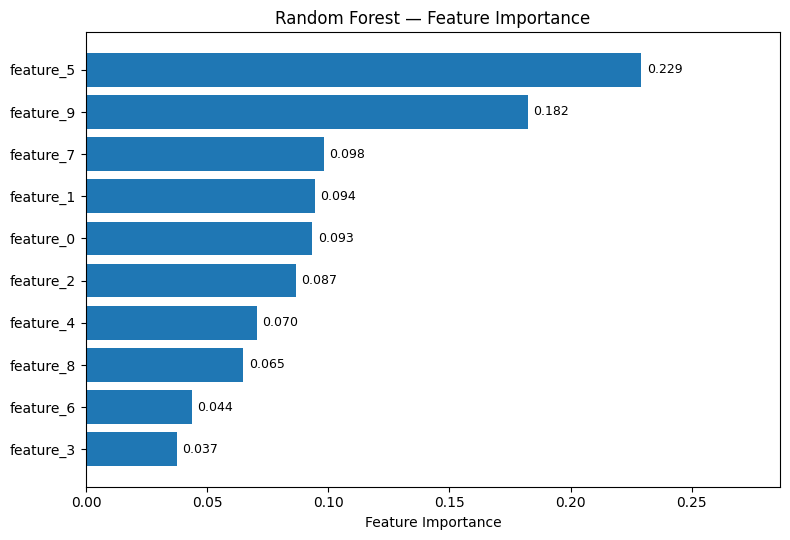

In [20]:
feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]
importances = rf_clf.feature_importances_

order = np.argsort(importances)   # ascending, per Chapter 16's barh convention
sorted_names = np.array(feature_names)[order]
sorted_importances = importances[order]

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(sorted_names, sorted_importances, color="tab:blue")

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.3f}", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)

ax.set_xlim(0, importances.max() * 1.25)
ax.set_xlabel("Feature Importance")
ax.set_title("Random Forest — Feature Importance")
plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- This is a direct, near-verbatim reuse of Chapter 16's `plot_ranked_bar`-style horizontal bar pattern — feature importance is precisely the canonical use case that chapter was building toward. The ascending-sort-for-`barh` convention is applied identically here.
- `rf_clf.feature_importances_` sums to `1.0` across all features (for scikit-learn's default impurity-based importance) — worth verifying (`importances.sum()`) as a quick sanity check that you're reading the right attribute correctly.

### Important Caveat: Impurity-Based Importance Has Known Biases
`.feature_importances_` (the default, impurity-based measure) is known to be **biased toward high-cardinality numerical/categorical features** — a feature with many unique values can appear artificially important purely due to having more possible split points, independent of its true predictive relationship with the target. **Permutation importance** (`sklearn.inspection.permutation_importance`) is a more robust, model-agnostic alternative that measures the actual drop in model performance when a feature's values are randomly shuffled — worth knowing as the "more rigorous" answer in an interview context, even though the visualization technique (a sorted horizontal bar chart) is identical either way.

### Common Mistakes
- Presenting feature importance as if it proves **causation** — a feature can be highly "important" to a model's predictions due to correlation with the true causal driver, without being the actual causal factor itself (the same correlation-≠-causation caveat from Chapter 45, now specifically relevant to model interpretability).
- Not being aware of impurity-based importance's high-cardinality bias, and over-trusting a ranking that might be partly an artifact of feature encoding choices rather than genuine predictive signal.
- Showing all 50+ features on one horizontal bar chart — becomes unreadable; show only the top-N (typically 10–20) most important features instead.

### Best Practices
- For a small number of features (as here), show all of them; for many features, show only the top-N.
- When importance rankings will inform a real business or product decision (not just internal model debugging), consider validating with permutation importance rather than relying solely on the default impurity-based measure.

### Interview Insight
**Q: What's a known limitation of scikit-learn's default `.feature_importances_` for tree-based models, and what's a more robust alternative?**
A: Impurity-based importance (the default) is biased toward high-cardinality features — those with many unique values get more opportunities to be selected as useful split points purely due to that cardinality, independent of true predictive value. Permutation importance is a more robust, model-agnostic alternative: it measures the actual drop in a chosen performance metric when each feature's values are randomly shuffled (breaking its relationship with the target) — a feature that's genuinely important causes a larger performance drop when shuffled.

### Mini Exercise
Sort and print `importances` alongside `feature_names` using `np.argsort(importances)[::-1]` (descending) as a plain printed table, and compare how much harder this is to scan quickly versus the horizontal bar chart above.

### Quiz (Chapter 59)
1. What Chapter-16 pattern does feature importance visualization directly reuse?
2. What known bias affects scikit-learn's default impurity-based feature importance?
3. What alternative importance measure addresses that bias, and how does it work conceptually?
4. Why doesn't high feature importance imply causation?


---
# CHAPTER 60 — MODEL COMPARISON VISUALIZATION

## 1. Concept
Comparing multiple models across multiple metrics simultaneously directly reuses Chapter 17's grouped-bar technique — now with real computed metrics instead of illustrative numbers.

## 2. Why It Matters
No single metric fully captures model quality — a fair comparison requires looking at several metrics (and, ideally, cost dimensions like training/inference time) side by side, since a model that wins on one metric may lose on another.


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import time

results = {}
for name, model, proba in [("Logistic Regression", log_reg, y_proba_lr), ("Random Forest", rf_clf, y_proba_rf)]:
    preds = (proba >= 0.5).astype(int)
    results[name] = {
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

results_df = pd.DataFrame(results).T   # models as rows, metrics as columns
print(results_df.round(3))


                     Precision  Recall     F1  ROC-AUC
Logistic Regression      0.644   0.500  0.563    0.887
Random Forest            0.894   0.776  0.831    0.956


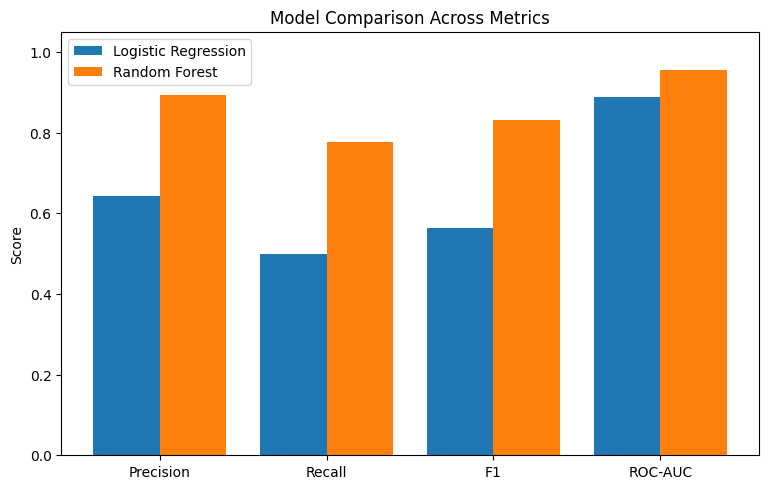

In [22]:
metrics_list = results_df.columns.tolist()
models_list = results_df.index.tolist()

x_pos = np.arange(len(metrics_list))
n_models = len(models_list)
bar_w = 0.8 / n_models

fig, ax = plt.subplots(figsize=(9, 5.5))
for i, model_name in enumerate(models_list):
    offset = (i - (n_models - 1) / 2) * bar_w
    ax.bar(x_pos + offset, results_df.loc[model_name], width=bar_w, label=model_name)

ax.set_xticks(x_pos)
ax.set_xticklabels(metrics_list)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model Comparison Across Metrics")
ax.legend()
plt.show()


### Line-by-Line Explanation
- This is the **identical offset-centering formula** from Chapter 17, now applied with `metrics_list` (not a fixed hardcoded list) driving `x_pos`, and `models_list` driving the number of grouped bars — proof that the general formula genuinely generalizes to any metric count and any model count with zero changes to the underlying math.
- `results_df = pd.DataFrame(results).T` — building the metrics as a dict-of-dicts and transposing is a clean, readable way to assemble a small models × metrics comparison table before visualizing it.

### Interpretation
Random Forest outperforms Logistic Regression on every metric shown here — a consistent sweep across Precision, Recall, F1, and ROC-AUC is a much stronger signal of genuine superiority than any single metric would be alone (echoing the exact interview point made back in Chapter 17).

### Common Mistakes
- Comparing models using only accuracy, especially under class imbalance (Chapter 51's setup) — misses the precision/recall tradeoff entirely and can favor a model that just predicts the majority class well.
- Not also comparing computational cost (training time, inference latency) when the business context cares about it — a marginally-better model that's 50x slower to serve in production may not actually be the right choice; consider adding these as additional bars/metrics when relevant.

### Best Practices
- Always compare across multiple metrics, not one.
- Sort/group metrics logically (e.g., all "quality" metrics together, separate from "cost" metrics like latency) if mixing metric types in one chart.

### Interview Insight
**Q: Model A wins on accuracy, Model B wins on recall. How would you communicate this comparison to a non-technical stakeholder using visualization?**
A: A grouped bar chart with one cluster per metric (accuracy, precision, recall, F1, etc.) and one bar per model within each cluster — this makes the tradeoff explicit and visual rather than requiring the stakeholder to mentally juggle several separate numbers, and naturally opens the conversation about which metric the business actually cares more about for this specific use case (e.g., "if missing a fraud case is costly, Model B's higher recall may matter more than Model A's higher accuracy").

### Mini Exercise
Add training time as a metric: time each model's `.fit()` call using `time.time()`, add it to `results_df` as a new column, and discuss (in a markdown cell) whether it changes which model you'd actually recommend deploying.

### Quiz (Chapter 60)
1. What Chapter-17 technique does this chapter directly reuse, and what changed about the inputs?
2. Why is comparing across multiple metrics more informative than a single metric, especially under class imbalance?
3. What non-quality dimension might also belong in a model comparison chart?


---
# CHAPTER 61 — HYPERPARAMETER VISUALIZATION

## 1. Concept
Plotting a single hyperparameter (e.g., `max_depth`, `n_estimators`) against a validation metric — as a **line plot**, since the hyperparameter is a meaningfully ordered continuous/discrete axis — reveals the tuning curve's shape: where performance improves, plateaus, or overfits.

## 2. Why It Matters
Grid/random search alone gives you the *best single value* found; the visualized curve additionally shows you the **shape** of the relationship — critical for judging how sensitive the model is to that hyperparameter, and whether the "best" value found is a robust plateau or a fragile spike.


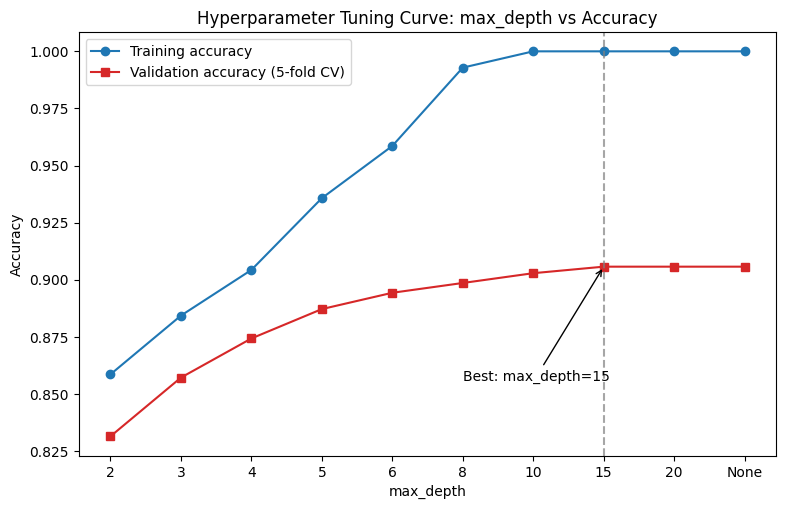

In [23]:
from sklearn.model_selection import cross_val_score

depth_values = [2, 3, 4, 5, 6, 8, 10, 15, 20, None]
depth_labels = [str(d) if d is not None else "None" for d in depth_values]
train_scores, val_scores = [], []

for depth in depth_values:
    model = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    val_scores.append(cross_val_score(model, X_train, y_train, cv=5).mean())

fig, ax = plt.subplots(figsize=(9, 5.5))
x_idx = np.arange(len(depth_values))
ax.plot(x_idx, train_scores, marker="o", label="Training accuracy", color="tab:blue")
ax.plot(x_idx, val_scores, marker="s", label="Validation accuracy (5-fold CV)", color="tab:red")

best_idx = int(np.argmax(val_scores))
ax.axvline(best_idx, color="gray", linestyle="--", alpha=0.7)
ax.annotate(f"Best: max_depth={depth_labels[best_idx]}",
            xy=(best_idx, val_scores[best_idx]), xytext=(best_idx - 2, val_scores[best_idx] - 0.05),
            arrowprops=dict(facecolor="black", arrowstyle="->"))

ax.set_xticks(x_idx)
ax.set_xticklabels(depth_labels)
ax.set_xlabel("max_depth")
ax.set_ylabel("Accuracy")
ax.set_title("Hyperparameter Tuning Curve: max_depth vs Accuracy")
ax.legend()
plt.show()


### Line-by-Line Explanation
- `cross_val_score(model, X_train, y_train, cv=5).mean()` — 5-fold cross-validation on the **training** set only (never touching `X_test`), producing a more robust validation estimate than a single held-out split; the test set is reserved for the truly final, one-time evaluation after all tuning is complete.
- Plotting **both** training and validation accuracy on the same axes (not just validation alone) is the key diagnostic move — the *gap* between them, not either curve in isolation, is what reveals overfitting (fully formalized as its own dedicated concept in Chapter 62's learning curves).
- `depth_labels` converts `None` (scikit-learn's "unlimited depth" value) to the string `"None"` for a legible x-tick — a small but necessary detail, since `None` can't be plotted as a numeric x-position directly alongside integers.

### Interpretation
Training accuracy climbs (and often approaches 1.0) as `max_depth` increases — deeper trees can always fit the training data better. Validation accuracy typically rises initially, then **plateaus or declines** past some depth — the point where it plateaus/declines, not where training accuracy is highest, marks the genuinely useful `max_depth` region; anything beyond that is overfitting the training set without improving (or actively hurting) generalization.

### Common Mistakes
- Tuning based on **training** score alone — always increases with model complexity and will lead you to pick an overfit configuration every time.
- Using a single train/validation split instead of cross-validation for the tuning curve — a single split's validation score can be noisy, especially on smaller datasets, potentially leading you to a hyperparameter choice that doesn't generalize to a re-run.
- Not marking/annotating the actually-selected value on the chart — forces the reader to visually estimate it rather than see it stated explicitly.

### Best Practices
- Always plot training AND validation performance together on hyperparameter tuning curves — the gap is the story.
- Use cross-validation (not a single split) for the validation curve whenever computationally feasible.
- Annotate the selected/recommended value directly on the chart.

### Interview Insight
**Q: Your `max_depth` tuning curve shows validation accuracy peaking at depth=10, but depth=6 has nearly identical validation accuracy with a much smaller train-validation gap. Which would you choose, and why?**
A: Likely depth=6 — a smaller train-validation gap at nearly identical validation performance suggests a more robust, less overfit model that's likely to generalize more reliably to genuinely new data, whereas the depth=10 peak might be partly fitting to noise specific to this particular cross-validation split. All else being roughly equal, preferring the simpler model with a smaller generalization gap (a form of Occam's razor) is generally the safer production choice.

### Mini Exercise
Rerun this tuning curve for `n_estimators` (try `[10, 25, 50, 100, 200, 400]`) instead of `max_depth`, keeping `max_depth` fixed at a reasonable value, and observe whether validation accuracy plateaus at a lower or higher relative point on this different hyperparameter's curve.

### Quiz (Chapter 61)
1. Why must the tuning curve be built from cross-validation scores, not the training set alone?
2. What does the training/validation *gap* (not either curve alone) reveal?
3. Why might you choose a hyperparameter value with a slightly lower validation score than the absolute peak?


---
# CHAPTER 62 — LEARNING CURVES

## 1. Concept
A learning curve plots training and validation score against **training set size** (not a hyperparameter, as in Chapter 61) — directly diagnosing whether a model would benefit from **more data**, and distinguishing high-bias (underfitting) from high-variance (overfitting) failure modes.

## 2. Why It Matters
This is one of the most practically important diagnostic charts in ML engineering: it directly answers "should we invest in collecting more training data, or is more data unlikely to help this model?" — a question with real cost implications that a single accuracy number cannot answer.


In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores_lc, val_scores_lc = learning_curve(
    RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    X_train, y_train, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8),
    random_state=42,
)

train_mean = train_scores_lc.mean(axis=1)
train_std = train_scores_lc.std(axis=1)
val_mean = val_scores_lc.mean(axis=1)
val_std = val_scores_lc.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(train_sizes, train_mean, marker="o", color="tab:blue", label="Training score")
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color="tab:blue")

ax.plot(train_sizes, val_mean, marker="s", color="tab:red", label="Validation score")
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2, color="tab:red")

ax.set_xlabel("Training Set Size")
ax.set_ylabel("Accuracy")
ax.set_title("Learning Curve — Random Forest (max_depth=6)")
ax.legend(loc="lower right")
plt.show()


### Line-by-Line Explanation
- `learning_curve(..., train_sizes=np.linspace(0.1, 1.0, 8), cv=5)` — scikit-learn trains and cross-validates the model at 8 different training-set-size fractions (10% up to 100% of `X_train`), returning a `(n_sizes, cv)` array of scores at each size — directly reusing the `.mean(axis=0/1)` + `fill_between` pattern from Chapter 25/27 to show both the central trend and its run-to-run variability.
- The shaded bands (± 1 std across CV folds) are exactly the Chapter 25/27 uncertainty-band pattern, now applied to a genuinely new ML-specific context — reinforcing that the same small set of Matplotlib techniques recombines across the entire course.

### The Diagnostic Reference — Reading the Curve's Shape
| Pattern | Diagnosis | Implication |
|---|---|---|
| Both curves converge to a **high** score | Good fit | Model has enough data and appropriate complexity |
| Both curves converge to a **low** score (small gap, both plateaued low) | **High bias** (underfitting) | More data won't help much — need a more expressive model or better features instead |
| Large, persistent gap between training (high) and validation (lower), especially one that hasn't closed by the largest training size | **High variance** (overfitting) | More data likely *would* help — the validation curve is often still rising and hasn't plateaued |
| Validation curve still rising steeply at the largest training size shown | Data-limited | Strong candidate for "collect more data" as the next investment |

### Interpretation
Check specifically whether the validation curve has visibly **plateaued** by the largest training size, or is **still rising** — a still-rising validation curve at max available data is the single strongest visual argument for "this model would likely improve with more training data," a very different diagnosis (and very different next engineering step) than "this model needs a different architecture/features," which a plateaued-but-low pair of curves would instead suggest.

### Common Mistakes
- Confusing a learning curve (x-axis = training set size) with a hyperparameter tuning curve (x-axis = a hyperparameter value, Chapter 61) — they answer fundamentally different questions and are easy to mix up by name alone.
- Concluding "we need more data" from a curve that has clearly already plateaued — a common, costly real-world mistake, since data collection is often expensive and this specific pattern indicates it likely won't help.
- Only running a single train/validation split at each size instead of cross-validation — introduces noise that can obscure whether the curve has genuinely plateaued or is just fluctuating.

### Best Practices
- Always run learning curves via cross-validation (as `learning_curve()` does internally) rather than single splits, given how consequential the "more data vs. different model" decision typically is.
- Present the shaded uncertainty band, not just the mean lines — the band's width itself is informative (wide bands at small training sizes are expected and normal).

### Interview Insight
**Q: Your team is debating whether to spend budget collecting 10x more labeled training data. How would a learning curve inform this decision?**
A: Plot training and validation score against training set size using cross-validation; if the validation curve is still visibly rising and hasn't plateaued at the current data volume, that's strong evidence more data would likely improve performance, justifying the investment. If instead both curves have already converged and plateaued (especially at a middling or low score — the high-bias pattern), more data of the same kind is unlikely to help much, and the better investment is probably a more expressive model, better features, or addressing label quality instead.

### Mini Exercise
Rerun the learning curve using a much shallower `max_depth=2` Random Forest and compare the resulting curve shape — expect to see the classic high-bias pattern (both curves converging to a lower plateau with a small gap) instead of the current setup's behavior.

### Quiz (Chapter 62)
1. What's on the x-axis of a learning curve, and how does that differ from a hyperparameter tuning curve?
2. What curve pattern indicates high bias (underfitting)? High variance (overfitting)?
3. What specific visual signal suggests that collecting more data would likely help?


---
# CHAPTER 63 — VALIDATION CURVES

## 1. Concept
`validation_curve()` is scikit-learn's dedicated utility for exactly the workflow built manually in Chapter 61 (sweep one hyperparameter, plot training vs. validation score) — this chapter formalizes it as its own named concept and shows the library-provided shortcut.

## 2. Why It Matters
Recognizing "hyperparameter tuning curve" and "validation curve" as the same underlying concept (just potentially using a convenience function vs. a manual loop) is itself a common point of terminology confusion worth resolving explicitly.


In [ ]:
from sklearn.model_selection import validation_curve

n_estimators_range = [10, 25, 50, 100, 200, 300]

train_scores_vc, val_scores_vc = validation_curve(
    RandomForestClassifier(max_depth=6, random_state=42),
    X_train, y_train,
    param_name="n_estimators", param_range=n_estimators_range,
    cv=5,
)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(n_estimators_range, train_scores_vc.mean(axis=1), marker="o", label="Training score", color="tab:blue")
ax.fill_between(n_estimators_range,
                 train_scores_vc.mean(axis=1) - train_scores_vc.std(axis=1),
                 train_scores_vc.mean(axis=1) + train_scores_vc.std(axis=1), alpha=0.15, color="tab:blue")

ax.plot(n_estimators_range, val_scores_vc.mean(axis=1), marker="s", label="Validation score", color="tab:red")
ax.fill_between(n_estimators_range,
                 val_scores_vc.mean(axis=1) - val_scores_vc.std(axis=1),
                 val_scores_vc.mean(axis=1) + val_scores_vc.std(axis=1), alpha=0.15, color="tab:red")

ax.set_xlabel("n_estimators")
ax.set_ylabel("Accuracy")
ax.set_title("Validation Curve: n_estimators (via sklearn.model_selection.validation_curve)")
ax.legend(loc="lower right")
plt.show()


### Line-by-Line Explanation
- `validation_curve(estimator, X, y, param_name=..., param_range=..., cv=5)` — the direct library equivalent of Chapter 61's manual `for depth in depth_values: ...` loop; it internally performs the same cross-validated fit-and-score sweep, just packaged as one function call returning `(train_scores, val_scores)` arrays shaped `(len(param_range), cv)`.
- **Terminology note**: "hyperparameter tuning curve" (Chapter 61) and "validation curve" (this chapter) describe the identical concept — the distinction that matters is only *how* you computed it (manual loop vs. this convenience function), not *what* it shows. Both produce and should be visualized identically: training + validation score vs. the swept hyperparameter, with `fill_between` uncertainty bands.

### Interpretation
Unlike `max_depth` (Chapter 61), `n_estimators` (number of trees) for a Random Forest typically shows validation score **rising and then plateauing** (rarely declining sharply) — more trees generally don't cause overfitting the way excessive depth does, since each individual tree's own capacity is unchanged; the practical tuning question here becomes "what's the smallest `n_estimators` that reaches the plateau," balancing accuracy against training/inference compute cost.

### Common Mistakes
- Treating `validation_curve()` and `learning_curve()` (Chapter 62) as interchangeable — they sweep fundamentally different things (a hyperparameter vs. training set size) and answer different questions; confusing them is a common but consequential terminology/API mistake.
- Sweeping `n_estimators` to an unnecessarily huge range once the validation curve has clearly plateaued — wastes compute for no accuracy benefit; the plateau point itself is the actionable "good enough" signal.

### Best Practices
- Use `validation_curve()` (the library function) over a manual loop whenever the sweep is over a single scikit-learn-compatible hyperparameter — less code, identical result, per the API-consistency argument scikit-learn's design generally favors.
- Once a validation curve plateaus, prefer the smallest hyperparameter value at (or near) that plateau — better generalization robustness and lower compute cost, for effectively the same validation performance.

### Interview Insight
**Q: What's the difference between a "learning curve" and a "validation curve," precisely?**
A: A learning curve's x-axis is **training set size** — it answers "would more data help?" A validation curve's x-axis is a **hyperparameter value** — it answers "what's the best setting for this specific hyperparameter, and how sensitive is performance to it?" They're visually similar (both plot training vs. validation score with uncertainty bands) but diagnose entirely different questions, and scikit-learn provides separate dedicated functions (`learning_curve()` vs `validation_curve()`) for each.

### Mini Exercise
Use `validation_curve()` to sweep `max_depth` (reusing Chapter 61's same `depth_values` list, minus the `None` entry since `validation_curve` requires uniformly comparable values) and confirm the resulting curve's shape matches the manually-built version from Chapter 61.

### Quiz (Chapter 63)
1. What's the precise conceptual difference between a learning curve and a validation curve?
2. What does `validation_curve()` return, and what shape are those arrays?
3. Why might `n_estimators`' validation curve rarely show sharp overfitting, unlike `max_depth`'s?


---
# CHAPTER 64 — EXPERIMENT VISUALIZATION

## 1. Concept
Real ML projects run many experiments (different models × hyperparameters × feature sets); visualizing them together — as a scatter of validation-score vs. training-time, colored/sized by other experiment attributes — supports comparing the full **cost-vs-performance tradeoff**, not just picking the single highest-scoring row in a spreadsheet.

## 2. Why It Matters
The "best" model by raw validation score alone is not always the right deployment choice once training time, inference latency, and model complexity/maintainability are factored in — an experiment-tracking visualization makes that full tradeoff visible at a glance.


In [ ]:
import time

experiment_configs = [
    {"name": "RF depth=4, n=50", "model": RandomForestClassifier(max_depth=4, n_estimators=50, random_state=1)},
    {"name": "RF depth=6, n=100", "model": RandomForestClassifier(max_depth=6, n_estimators=100, random_state=1)},
    {"name": "RF depth=10, n=200", "model": RandomForestClassifier(max_depth=10, n_estimators=200, random_state=1)},
    {"name": "RF depth=None, n=300", "model": RandomForestClassifier(max_depth=None, n_estimators=300, random_state=1)},
    {"name": "LogReg", "model": LogisticRegression(max_iter=1000)},
]

exp_results = []
for cfg in experiment_configs:
    start = time.time()
    cfg["model"].fit(X_train, y_train)
    train_time = time.time() - start
    val_score = cross_val_score(cfg["model"], X_train, y_train, cv=5).mean()
    exp_results.append({"name": cfg["name"], "train_time": train_time, "val_score": val_score})

exp_df = pd.DataFrame(exp_results)
print(exp_df.round(4))


In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

sc = ax.scatter(exp_df["train_time"], exp_df["val_score"], s=200, c=range(len(exp_df)), cmap="tab10", alpha=0.8, edgecolors="black")

for _, row in exp_df.iterrows():
    ax.annotate(row["name"], xy=(row["train_time"], row["val_score"]),
                xytext=(6, 4), textcoords="offset points", fontsize=9)

ax.set_xlabel("Training Time (seconds)")
ax.set_ylabel("Validation Accuracy (5-fold CV)")
ax.set_title("Experiment Comparison: Accuracy vs Training Cost")
plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- Every experiment's configuration and results are collected into a **list of dicts → DataFrame** — the standard, clean pattern for accumulating experiment-tracking data before visualization (and the natural shape to log to a file/database in a real MLOps setup).
- `ax.scatter(..., s=200, ...)` plus per-point `ax.annotate()` (Chapter 33's programmatic-labeling pattern, applied here to *every* point rather than just the extremes, since with only 5 experiments all labels remain legible) directly turns a plain scatter into a fully-labeled experiment comparison chart.

### Interpretation
Points toward the **top-left** are the ideal experiments — high validation accuracy at low training cost; points toward the **bottom-right** represent poor tradeoffs (expensive but not especially accurate) that should be deprioritized. This framing directly supports a genuine engineering decision ("which configuration do we actually deploy/scale up?") beyond just "which had the single highest score."

### Common Mistakes
- Tracking and comparing only validation score across experiments, discarding training/inference time information — loses the ability to make an informed cost-vs-performance tradeoff decision later.
- Not annotating points directly, forcing the reader to cross-reference a separate legend/table to identify each experiment — fine for 3–4 points, but becomes essential as experiment count grows past what a legend can cleanly hold.

### Best Practices
- Log both performance AND cost metrics for every experiment from the start of a project, even if cost doesn't seem to matter yet — it's far cheaper to have it available and unused than to need it later and have to re-run experiments.
- Prefer direct point annotation over a separate legend once experiment count is small enough for labels to stay legible (roughly ≤10); switch to color-coded groups + a legend beyond that.

### Interview Insight
**Q: Two experiments — Model A has 91% validation accuracy and takes 2 minutes to train; Model B has 92% accuracy and takes 45 minutes to train. How would you present this tradeoff, and which would you recommend?**
A: A scatter of validation score vs. training time (or inference latency, if that's the more relevant production cost) makes the tradeoff immediately visible rather than burying it in a table. The recommendation genuinely depends on context — if retraining frequency and iteration speed matter (common early in a project), Model A's minor accuracy sacrifice for a 20x+ speedup is very likely the better choice; if this is a one-time training run for a system where marginal accuracy gains have high business value and retraining is rare, Model B could be justified. The visualization's job is to make that tradeoff explicit so the actual business context can decide it, not to declare a single "winner" automatically.

### Mini Exercise
Add a `test_score` column (evaluate each fitted model on `X_test`/`y_test` after the loop) to `exp_df`, and re-plot with point **size** instead encoding `test_score` (in addition to color encoding the categorical experiment name) — producing a 4-dimension experiment chart similar in spirit to Chapter 44's multivariate techniques.

### Quiz (Chapter 64)
1. Why should you track training/inference cost alongside validation performance for every experiment, even if cost doesn't seem to matter yet?
2. What region of the accuracy-vs-training-time scatter represents the best tradeoff?
3. When should you switch from direct point annotation to a color-coded legend for an experiment comparison chart?


---
# CHAPTER 65 — ERROR ANALYSIS

## 1. Concept
Error analysis visualizes **where and how** a model is wrong, sliced by meaningful subgroups — not just an aggregate error rate. This directly answers "is this model equally reliable across all segments, or does it silently fail for a specific subgroup?"

## 2. Why It Matters
An aggregate metric can look acceptable while hiding a model that performs terribly for a specific, business-critical segment (a particular region, customer type, or feature range) — a pattern with serious fairness, reliability, and business-risk implications if it goes undetected before deployment.


In [ ]:
np.random.seed(30)
segment = np.random.choice(["Segment A", "Segment B", "Segment C", "Segment D"], size=len(y_test),
                            p=[0.4, 0.3, 0.2, 0.1])

error_df = pd.DataFrame({
    "segment": segment,
    "true_label": y_test,
    "predicted": (y_proba_rf >= 0.5).astype(int),
    "predicted_proba": y_proba_rf,
})
error_df["correct"] = (error_df["true_label"] == error_df["predicted"])

error_rate_by_segment = error_df.groupby("segment")["correct"].apply(lambda s: 1 - s.mean()).sort_values(ascending=False)
segment_counts = error_df["segment"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(error_rate_by_segment.index, error_rate_by_segment.values, color="tab:red")
for bar, seg in zip(bars, error_rate_by_segment.index):
    n = segment_counts[seg]
    axes[0].annotate(f"n={n}", xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                      xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
axes[0].set_ylabel("Error Rate")
axes[0].set_title("Error Rate by Segment (with sample size)")
axes[0].tick_params(axis="x", rotation=15)

# False negatives specifically, by segment (often the more business-critical error type)
fn_by_segment = error_df[(error_df["true_label"] == 1) & (error_df["predicted"] == 0)]["segment"].value_counts()
axes[1].bar(fn_by_segment.index, fn_by_segment.values, color="tab:orange")
axes[1].set_ylabel("False Negative Count")
axes[1].set_title("False Negatives by Segment")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `error_df.groupby("segment")["correct"].apply(lambda s: 1 - s.mean())` — a direct application of Pandas `groupby` (assumed prior knowledge, per this course's stated prerequisites) to compute a per-segment error rate, immediately visualized rather than left as a table.
- Annotating each bar with its segment's sample size (`n=`) is **essential** here specifically: an error rate computed from a tiny segment (e.g., `n=8`) is far noisier and less trustworthy than one from a large segment (`n=500`) — showing `n` prevents over-reacting to a high error rate that might just be small-sample noise, directly connecting back to Chapter 27's standard-error reasoning.
- The second panel isolates **false negatives specifically** (not overall errors) by segment — because, per Chapter 53's cost-asymmetry point, FN and FP often matter very differently, so error analysis frequently needs to look at one specific error *type*, not just aggregate error rate, to be actionable.

### Interpretation
If one segment shows a meaningfully higher error rate (backed by a reasonably large `n`, not just a handful of noisy samples), that's a concrete, investigable finding — is that segment underrepresented in training data? Does it have systematically different feature distributions? This is exactly the kind of subgroup analysis that responsible ML deployment requires before shipping a model that will affect real people or business decisions differently across segments.

### Common Mistakes
- Reporting a segment's error rate without its sample size — a segment with `n=5` and 40% error rate is statistically almost meaningless noise; the same 40% rate from `n=500` is a serious, real finding. Never present one without the other.
- Only ever looking at aggregate error rate and never disaggregating by any subgroup — the single most common gap between "the model looked fine in testing" and "the model failed unexpectedly for a specific group in production."
- Treating a discovered high-error segment purely as a technical curiosity rather than escalating it as a potential fairness/reliability/business-risk issue requiring further investigation before deployment.

### Best Practices
- Always disaggregate error analysis by every meaningful business segment/subgroup available (region, customer tier, demographic categories where legally/ethically appropriate, time period, etc.) — not just report one aggregate number.
- Always show sample size alongside any segment-level rate.
- Look at specific error *types* (FN vs FP), not just overall error rate, when the business cost of each type differs — as demonstrated in the second panel above.

### Interview Insight
**Q: Your model has 92% overall accuracy, but a stakeholder asks whether it's equally reliable for all customer segments. How would you investigate and communicate the answer?**
A: Disaggregate the error rate (and, if the error types have different business costs, the false-negative/false-positive rates specifically) by every relevant segment, visualized as a bar chart with each segment's sample size annotated directly on the chart — sample size matters because a high error rate from a tiny segment could just be noise, while the same rate from a large segment is a genuine, actionable finding. This turns a single aggregate metric into a concrete, segment-level reliability picture that can directly inform whether the model is safe to deploy uniformly or needs segment-specific attention (more training data for that segment, a fairness-aware retraining approach, or a documented limitation) before going live.

### Mini Exercise
Compute and visualize the **false positive** count by segment (mirroring the false-negative panel above, but filtering `true_label == 0` and `predicted == 1` instead), and compare which segment has more FN vs. more FP — discuss, in a markdown cell, whether that asymmetry itself is meaningful given this course's earlier point about differing FN/FP business costs.

### Quiz (Chapter 65)
1. Why must sample size always be shown alongside a segment's error rate?
2. Why might error analysis need to separate false negatives from false positives rather than reporting only overall error rate?
3. What real-world risk does undetected segment-level error disparity create?

### Chapter 65 Summary
- Error analysis disaggregates model performance by meaningful subgroups, always paired with sample size, to catch reliability problems an aggregate metric would hide.
- Separating error types (FN vs FP) by segment connects directly back to the cost-asymmetry reasoning established in the confusion matrix chapter (53).

---

## END OF NOTEBOOK 7 — What You Should Now Be Able To Do
- Build a threshold-vs-metric chart and reason about *why* the "best F1" threshold isn't automatically the right business choice.
- Build and correctly interpret actual-vs-predicted and residual plots for regression, including the critical `set_aspect('equal')` detail.
- Diagnose heteroscedasticity, missing non-linearity, and systematic bias directly from a residual plot's shape.
- Build feature importance charts and articulate the impurity-based-importance bias and the permutation-importance alternative.
- Compare multiple models across multiple metrics using the general grouped-bar pattern, and know when cost metrics belong in that comparison too.
- Build hyperparameter tuning curves, learning curves, and validation curves — and correctly distinguish what each one's x-axis actually represents and what question each answers.
- Build an experiment-tracking visualization balancing performance against training/inference cost.
- Run a proper segment-level error analysis, always paired with sample size, separating error types by their differing business costs.

## Before Moving to Notebook 8 (Chapters 66–75: Data Leakage Visualization, Data Drift Visualization, Outlier Detection, Missing Data Visualization, Categorical Data Visualization, Time-Series Visualization, Rolling Statistics, Multi-Panel Time Series, Professional EDA Notebook, Matplotlib Debugging)
 